# 05 - Parameter estimation sensitivity (Tests 1 and 3)

**Research question.** How much do optimal weights move because of *estimation noise alone*, and are the movements economically large?

**Design.**
1. *Sampling sensitivity:* block-bootstrap one estimation window and re-optimise. The spread of the resulting weights is the weight uncertainty implied by a single finite sample.
2. *Controlled input perturbation:* shift means by multiples of their standard error (one SE is the natural unit of noise).
3. *Time stability:* rolling weights across windows (turnover, effective N).

Measures:
$L_1$ distance $\sum_i|w_i-w_i^0|$, turnover-equivalent $\tfrac12 L_1$, concentration (HHI, effective N), change in risk.

In [10]:
import sys, warnings
import os
from pathlib import Path
try:  
    os.chdir(Path(__vsc_ipynb_file__).resolve().parent)
except NameError:  
    pass
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import data_processing as dp, covariance_estimators as ce, portfolio_models as pm
from src import stability_tests as st, regime_detection as rd, stress_testing as sx, evaluation as ev
from src.backtesting import walk_forward, make_models, in_sample_vs_out_of_sample
plt.rcParams["figure.dpi"] = 110
_candidates = ["returns_simple_daily.csv", "returns_daily.csv"]
_path = next((Path("../data/processed") / f for f in _candidates if (Path("../data/processed") / f).exists()), None)
if _path is None:
    raise FileNotFoundError("Run notebook 01 first: expected ../data/processed/returns_simple_daily.csv")
returns = pd.read_csv(_path, index_col=0, parse_dates=True)
print("loaded:", _path.name)
X = returns.to_numpy()
WINDOW = 504
print(returns.shape, returns.index[0].date(), "->", returns.index[-1].date())

loaded: returns_simple_daily.csv
(3519, 5) 2012-01-04 -> 2025-12-31


## 1. Sampling sensitivity on the latest window

In [11]:
last = X[-WINDOW:]
rows = {}
for m in pm.CORE_TEN:
    r = st.weight_sensitivity_to_sampling(pm.MODELS[m], last, n_boot=200)
    rows[m] = {"mean_L1": r["mean_L1_distance"], "turnover_equiv": r["mean_turnover_equiv"],
               "avg_weight_std": float(np.mean(r["w_boot_std"])), "n_ok": r["n_success"]}
sens = pd.DataFrame(rows).T
sens_summary = sens.sort_values("turnover_equiv").round(3)
from pathlib import Path
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\core_model_weight_sensitivity.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
sens_summary.to_csv(table_path)
sens_summary

,mean_L1,turnover_equiv,avg_weight_std,n_ok
equal_weight,0.000,0.000,0.000,200.0
ledoit_wolf_minvar,0.049,0.025,0.012,200.0
gmv_long_only,0.053,0.026,0.013,200.0
risk_parity,0.063,0.032,0.015,200.0
min_vol_capped,0.137,0.068,0.034,200.0
cond_vol_minvar,0.218,0.109,0.041,200.0
mean_variance,0.273,0.136,0.074,200.0
black_litterman,0.399,0.200,0.154,200.0
robust_mv,0.451,0.225,0.131,200.0
max_sharpe,0.558,0.279,0.145,200.0


**Interpret:** rank the models by sampling sensitivity. Is the ordering what the *input requirements* predicted (models using $\mu$ vs only $\Sigma$)? Which model is most affected and by roughly how many percent of the portfolio?

*Models that use expected returns were generally more sensitive than those using only covariance. **Maximum Sharpe** was most sensitive: its weights shifted by about **28% of the portfolio** on average. Equal weight did not change.*

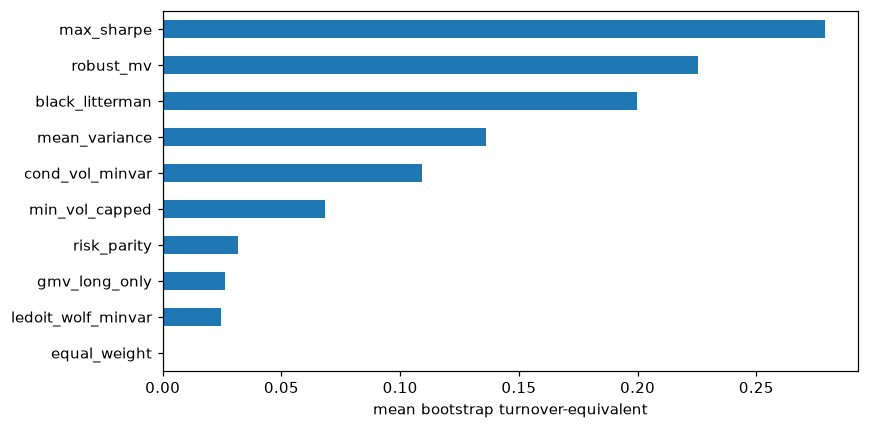

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
sens["turnover_equiv"].sort_values().plot(kind="barh", ax=ax); ax.set_xlabel("mean bootstrap turnover-equivalent"); plt.tight_layout()
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\bootstrap_weight_sensitivity.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")

## 2. Weight response to mean perturbation (in standard errors)

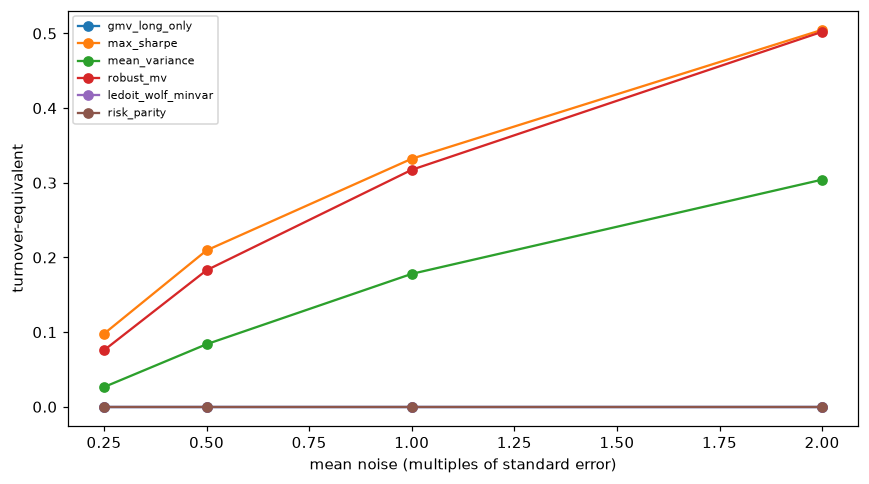

In [13]:
levels = [0.25, 0.5, 1.0, 2.0]
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in ["gmv_long_only", "max_sharpe", "mean_variance", "robust_mv", "ledoit_wolf_minvar", "risk_parity"]:
    df = sx.weight_response(pm.MODELS[m], last, lambda x, lev, rng: sx.perturb_mean(x, lev, rng),
                            levels=levels, n_rep=40)
    g = df.groupby("level")["turnover_equiv"].mean()
    ax.plot(g.index, g.values, marker="o", label=m)
ax.set_xlabel("mean noise (multiples of standard error)"); ax.set_ylabel("turnover-equivalent"); ax.legend(fontsize=7)
plt.tight_layout()
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\mean_perturbation_sensitivity.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")

**Interpret:** compare the slopes. A model whose weights barely react to $\mu$ noise is also *ignoring* information in $\mu$; discuss that trade-off between robustness and responsiveness.

**Interpretation:** As mean noise increases, maximum-Sharpe and robust mean-variance weights change the most; mean-variance changes less. GMV, Ledoit–Wolf, and risk parity barely react because they do not use expected returns. This makes them more stable, but they also ignore information in expected returns that could improve the portfolio if those estimates are accurate.

## 3. Does the covariance estimator matter? (same optimiser, different Sigma)

In [14]:
rows = {}
for name, est in ce.ESTIMATORS.items():
    f = lambda x, e=est: pm.gmv_long_only(x, cov_estimator=e)
    r = st.weight_sensitivity_to_sampling(f, last, n_boot=100)
    rows[name] = {"turnover_equiv": r["mean_turnover_equiv"], "cond": ce.condition_number(est(last))}
estimator_sensitivity = pd.DataFrame(rows).T.round(3)
from pathlib import Path
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\covariance_estimator_weight_sensitivity.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
estimator_sensitivity.to_csv(table_path)
estimator_sensitivity

,turnover_equiv,cond
sample,0.026,33.810
ledoit_wolf,0.025,17.098
oas,0.028,28.929
const_corr_0.5,0.023,28.971
ewma_0.94,0.107,94.831


## 4. Weight stability over time (rolling vs expanding)

In [15]:
mods = {m: pm.MODELS[m].fn for m in ["gmv_long_only", "max_sharpe", "ledoit_wolf_minvar", "risk_parity", "robust_mv"]}
models = make_models(mods)
roll = walk_forward(returns, models, window=WINDOW, rebalance_every=21)
expd = walk_forward(returns, models, window=WINDOW, rebalance_every=21, expanding=True)
tab = pd.concat({"rolling": st.weight_stability_summary(roll.weights),
                 "expanding": st.weight_stability_summary(expd.weights)})
tab_summary = tab.round(3)
from pathlib import Path
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\rolling_expanding_weight_stability_summary.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
tab_summary.to_csv(table_path)
tab_summary

mean_turnover  p95_turnover  mean_weight_std  \
rolling   gmv_long_only               0.008         0.022            0.020   
          max_sharpe                  0.098         0.352            0.193   
          ledoit_wolf_minvar          0.012         0.025            0.031   
          risk_parity                 0.008         0.022            0.035   
          robust_mv                   0.118         0.296            0.186   
expanding gmv_long_only               0.002         0.006            0.008   
          max_sharpe                  0.015         0.044            0.054   
          ledoit_wolf_minvar          0.002         0.006            0.009   
          risk_parity                 0.002         0.005            0.019   
          robust_mv                   0.045         0.152            0.092   

                              mean_HHI  mean_effective_N  max_single_weight  \
rolling   gmv_long_only          0.838             1.196              0.966   
          max_sharpe             0.594             1.804              1.000   
          ledoit_wolf_minvar     0.755             1.335              0.934   
          risk_parity            0.338             3.047              0.639   
          robust_mv              0.563             1.974              1.000   
expanding gmv_long_only          0.851             1.177              0.944   
          max_sharpe             0.573             1.801              0.824   
          ledoit_wolf_minvar     0.823             1.217              0.927   
          risk_parity            0.382             2.651              0.639   
          robust_mv              0.635             1.695              1.000   

                              min_single_weight  
rolling   gmv_long_only                   0.000  
          max_sharpe                      0.000  
          ledoit_wolf_minvar              0.000  
          risk_parity                     0.076  
          robust_mv                       0.000  
expanding gmv_long_only                   0.000  
          max_sharpe                      0.000  
          ledoit_wolf_minvar              0.000  
          risk_parity                     0.081  
          robust_mv                       0.000

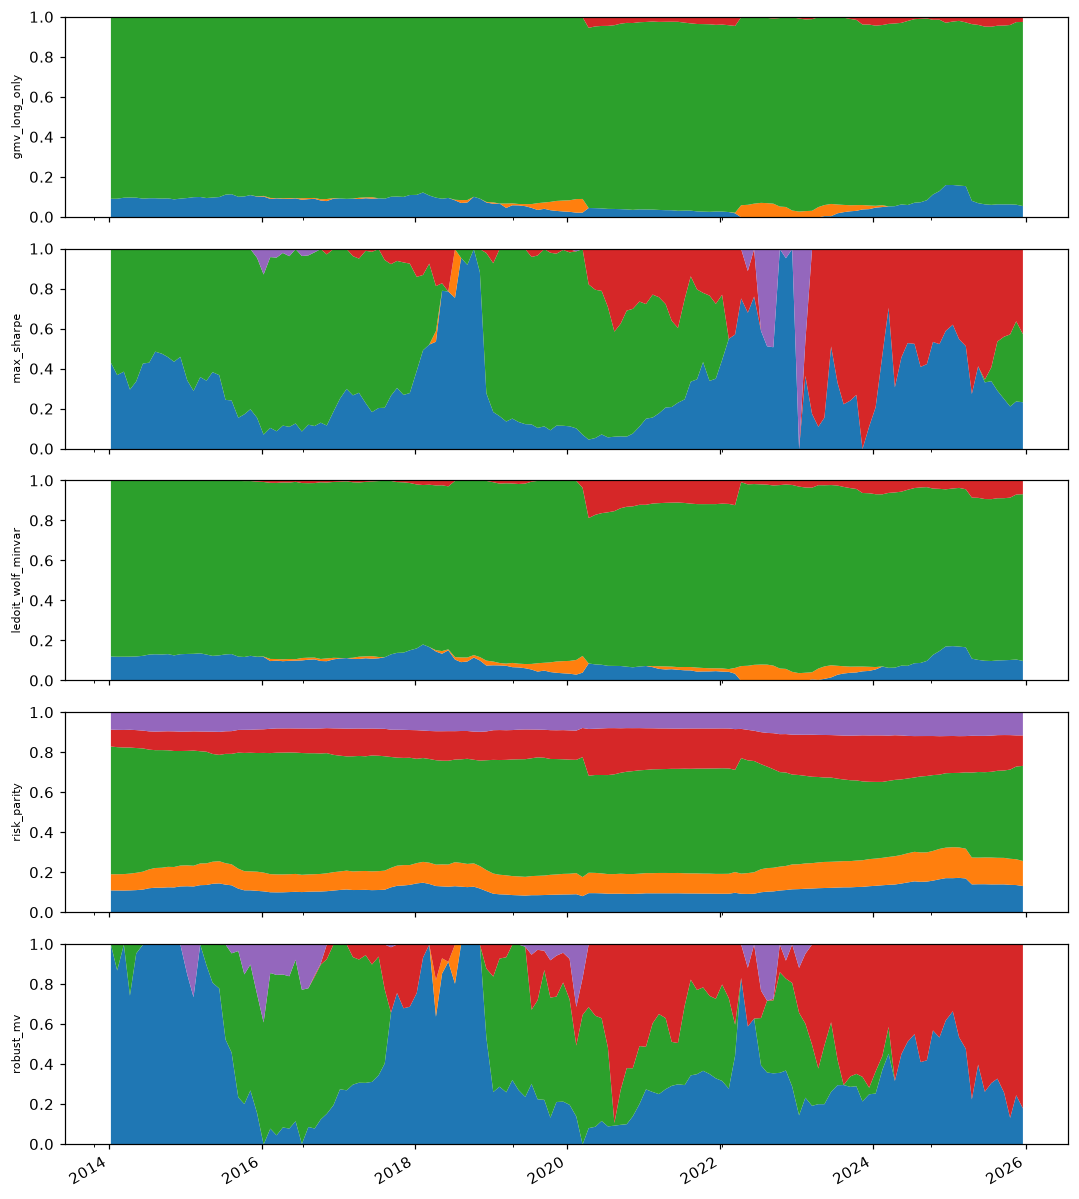

In [16]:
fig, ax = plt.subplots(len(models), 1, figsize=(10, 2.2 * len(models)), sharex=True)
for a, m in zip(ax, models):
    roll.weights[m].plot.area(ax=a, legend=False, lw=0); a.set_ylabel(m, fontsize=7); a.set_ylim(0, 1)
plt.tight_layout()
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\rolling_weight_paths.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")

**Your turn:** (i) Which choice - rolling or expanding - gives more stable weights and why? (ii) Does stable *weights* imply a *valid* model? Construct an argument that a model could be perfectly stable and still structurally invalid.


**Interpretation:** An expanding window usually gives more stable weights because it uses more observations, reducing the effect of any one noisy period. A rolling window adapts faster to recent market changes, but its weights may fluctuate more.

Stable weights do not necessarily mean a model is valid. For example, equal weighting is perfectly stable by construction, but it may fail to reflect changing risks and correlations. Stability is only one quality to assess; the model must also represent the market well and perform reliably out of sample.


## Notebook 05 summary

`Notebook 05: Parameter estimation sensitivity` asks how much portfolio weights change when estimates change, and whether those changes are meaningful.

- **Data and setup:** 3,519 daily return observations for 5 ETFs, from January 2012 to December 2025. The main analyses use the latest 504 trading days.
- **Sampling uncertainty:** The notebook bootstraps that latest window and recalculates weights 200 times. Equal weight is unchanged; Ledoit–Wolf minimum variance, GMV, and risk parity are least sensitive. Maximum Sharpe is most sensitive, with an average turnover-equivalent change of about **28%**. All 200 bootstrap runs succeeded for each model.
- **Noisy expected returns:** When expected returns are perturbed, maximum-Sharpe and robust mean-variance weights change the most. GMV, Ledoit–Wolf minimum variance, and risk parity barely respond because they do not use expected-return estimates. This makes them less sensitive to mean-estimation noise, but also means they cannot benefit from accurate return forecasts.
- **Covariance estimators:** For the GMV portfolio, most covariance estimators produce similar bootstrap weight changes. EWMA is more sensitive: its turnover-equivalent change is **0.107**, compared with roughly **0.023–0.028** for the others.
- **Stability over time:** Expanding-window weights generally have lower turnover than rolling-window weights because they use more data. Risk parity is more diversified (effective number of assets around 3) than GMV and Ledoit–Wolf minimum variance (around 1.2–1.3). Maximum-Sharpe and robust-MV weights show greater turnover.

**Overall takeaway:** Portfolios that rely on expected returns are more vulnerable to estimation noise. Expanding windows can make weights steadier, but stability alone does not establish that a model is valid—an unchanged allocation can still fail to reflect risk or perform reliably out of sample.